In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv('/content/smartcart_dataset.csv')

print("Shape:", df.shape)
print(df["category"].value_counts())
df.head()

Shape: (1200, 6)
category
Apparel        400
Electronics    400
Grocery        400
Name: count, dtype: int64


,price,weight_kg,rating,discount_pct,description_length,category
0,438.29,3.413,4.1,57.5,47,Apparel
1,719.57,6.111,3.5,46.5,45,Apparel
2,1202.48,9.337,4.1,23.7,109,Electronics
3,316.98,2.752,4.4,21.9,20,Grocery
4,2037.38,6.407,3.6,14.1,93,Electronics


<Axes: xlabel='price', ylabel='weight_kg'>

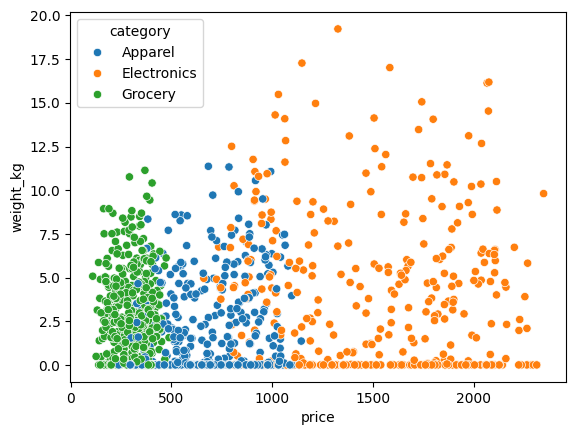

In [18]:
sns.scatterplot(data=df, x='price', y='weight_kg', hue='category')

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

FEATURES = ['price', 'weight_kg', 'rating', 'discount_pct', 'description_length']
TARGET = 'category'

X = df[FEATURES]
y_raw = df[TARGET]
le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_
print(dict(zip(range(len(class_names)), class_names)))

{0: 'Apparel', 1: 'Electronics', 2: 'Grocery'}


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train.shape, X_test.shape

((960, 5), (240, 5))

In [21]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

perceptron = Sequential()
perceptron.add(Dense(3, activation='softmax', input_dim=X_train.shape[1]))

perceptron.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 3)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18 (72.00 B)

 Trainable params: 18 (72.00 B)

 Non-trainable params: 0 (0.00 B)

In [22]:
perceptron.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])
history_p = perceptron.fit(X_train, y_train, epochs=100,
                            validation_split=0.2, verbose=0)

In [23]:
weights, bias = perceptron.layers[0].get_weights()
print('weights:\n', weights)
print('bias:\n', bias)

weights:
 [[-0.36182582  0.7015466  -0.5447188 ]
 [-0.2348608   0.32364136  0.2038514 ]
 [-0.20337155  0.48212355 -0.0905065 ]
 [ 0.40556368 -0.8017673  -1.6659368 ]
 [ 0.32341653  1.5632898  -0.29099151]]
bias:
 [ 0.20091906 -0.00552527 -0.22239858]


In [24]:
perceptron_loss, perceptron_acc = perceptron.evaluate(X_test, y_test, verbose=0)
print(f'Perceptron test accuracy: {perceptron_acc:.3f}')

Perceptron test accuracy: 0.867


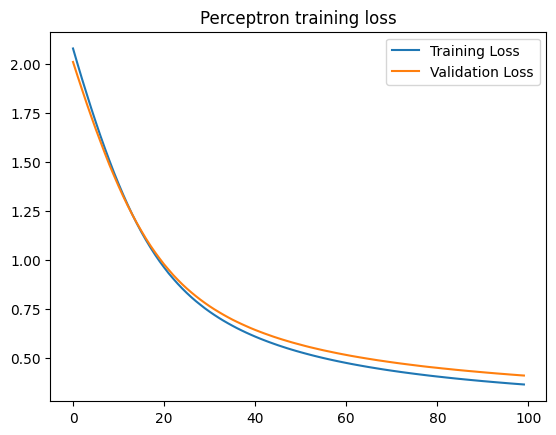

In [25]:
plt.plot(history_p.history['loss'], label='Training Loss')
plt.plot(history_p.history['val_loss'], label='Validation Loss')
plt.title('Perceptron training loss')
plt.legend()
plt.show()

In [26]:
ann = Sequential()
ann.add(Dense(32, activation='relu', input_dim=X_train.shape[1]))
ann.add(Dense(16, activation='relu'))
ann.add(Dense(3, activation='softmax'))

ann.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 771 (3.01 KB)

 Trainable params: 771 (3.01 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
ann.compile(optimizer='adam',
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
history_ann = ann.fit(X_train, y_train, epochs=100,
                       validation_split=0.2, verbose=0)
ann_loss, ann_acc = ann.evaluate(X_test, y_test, verbose=0)
print(f'ANN test accuracy: {ann_acc:.3f}')

ANN test accuracy: 0.933


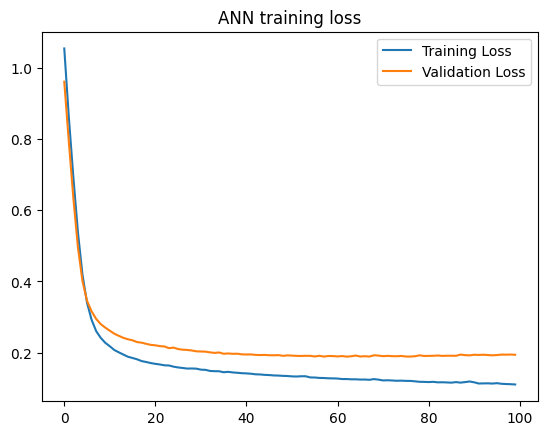

In [28]:
plt.plot(history_ann.history['loss'],
label='Training Loss')
plt.plot(history_ann.history['val_loss'],
label='Validation Loss')
plt.title('ANN training loss')
plt.legend()
plt.show()

In [29]:

# Extra
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Code
log_reg = LogisticRegression(max_iter=2000)
log_reg.fit(X_train, y_train)
y_pred_logreg = log_reg.predict(X_test)
logreg_acc = accuracy_score(y_test, y_pred_logreg)

print(f"Logistic Regression test accuracy: {logreg_acc:.3f}\n")
print(classification_report(y_test, y_pred_logreg, target_names=class_names))

Logistic Regression test accuracy: 0.925

              precision    recall  f1-score   support

     Apparel       0.92      0.85      0.88        80
 Electronics       0.94      0.95      0.94        80
     Grocery       0.92      0.97      0.95        80

    accuracy                           0.93       240
   macro avg       0.92      0.92      0.92       240
weighted avg       0.92      0.93      0.92       240



NameError: name 'y_pred_perceptron' is not defined

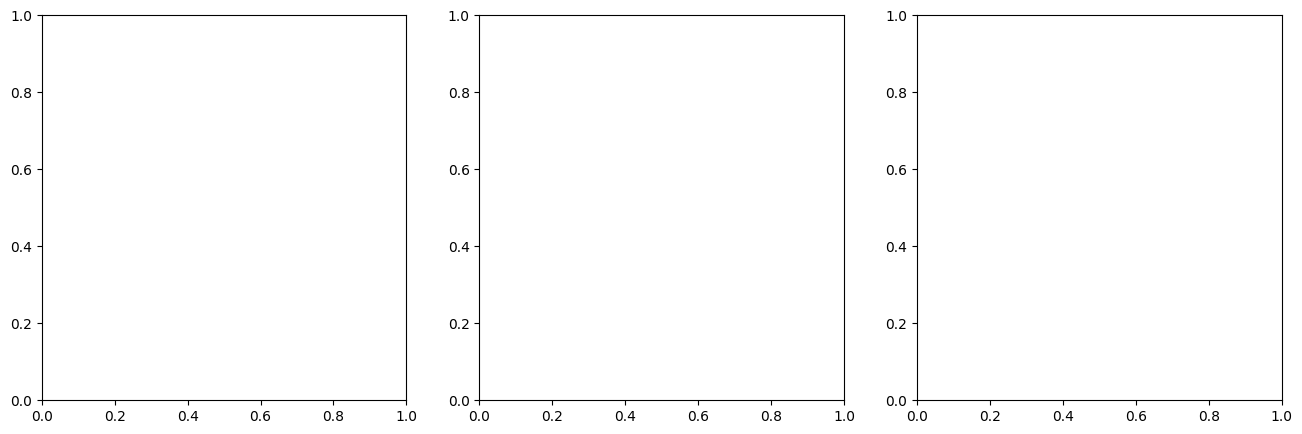

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, y_pred, title, cmap in zip(
        axes,
        [y_pred_perceptron, y_pred_ann, y_pred_logreg],
        ['Perceptron -- Confusion Matrix', 'ANN -- Confusion Matrix',
        'Logistic Regression -- Confusion Matrix'],
        ['Blues', 'Greens', 'Oranges']):
    cm = confusion_matrix(y_test, y_pred)
    im = ax.imshow(cm, cmap=cmap)
    ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(title)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Perceptron (Keras)', 'Logistic Regression (sklearn)',
              'ANN (Keras)'],
    'Test Accuracy': [perceptron_acc,logreg_acc ,ann_acc ]})
comparison

In [ ]:
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
df = pd.read_csv("smartcart_dataset.csv")
FEATURES = ["price", "weight_kg","rating", "discount_pct", "description_length"]

TARGET = "category"
df.head()

In [ ]:

X = df[FEATURES].values
y_raw = df[TARGET].values

label_encoder = LabelEncoder()            # Encode target labels
y = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_
Copy
X = df[FEATURES].values
y_raw = df[TARGET].values

label_encoder = LabelEncoder()                      # Encode target labels
y = label_encoder.fit_transform(y_raw)
class_names = label_encoder.classes_

X_train, X_test, y_train, y_test =                  # Split data into training & testing
    train_test_split(
    X, y,test_size=0.2, random_state=42,
    stratify=y)

scaler = StandardScaler()                           # Scale input features
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_tf = tf.convert_to_tensor(X_train_scaled,   # Convert data into Tensors
dtype=tf.float32)
y_train_tf = tf.convert_to_tensor(y_train,
dtype=tf.int32)

X_test_tf = tf.convert_to_tensor(X_test_scaled,
dtype=tf.float32)
y_test_tf = tf.convert_to_tensor(y_test,
dtype=tf.int32

In [ ]:
model = Sequential()

model.add(Dense(32, activation="relu", input_dim=X_train_scaled.shape[1]))
model.add(Dense(16, activation="relu"))
model.add(Dense(3, activation="softmax"))

model.summary()

In [ ]:
def forward(model, X):
    return model(X, training=True)

In [ ]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()
def compute_loss(y_true, y_pred):
    return loss_fn(y_true, y_pred)

In [ ]:
def backward(model, X, y_true):
    with tf.GradientTape() as tape:
        y_pred = forward(model, X)
        loss = compute_loss(y_true, y_pred)

    gradients = tape.gradient(loss, model.trainable_variables)
    return loss, gradients

In [ ]:
optimizer = keras.optimizers.SGD(learning_rate=0.1)

def update(model, gradients, optimizer):
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

In [ ]:
loss_history = []
for epoch in range(500):
    loss, gradients = backward(model, X_train_tf, y_train_tf)
    update(model, gradients, optimizer)

    loss_history.append(float(loss))

    if epoch % 50 == 0:
        print(f"Epoch {epoch:4d} │ Loss: {float(loss):.4f}")
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy loss")
plt.title("SmartCart ANN (Keras) — manual GradientTape training loop loss")
plt.show()

In [ ]:
test_probs = model(X_test_tf, training=False)       # no training here

y_pred = np.argmax(test_probs.numpy(), axis=1)      # highest-probability class

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))